# Import

In [45]:

from collections import Counter
from collections import defaultdict

# Base
import math as m

# Base 2.0
import numpy as np
import pandas as pd

# Grafici
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns
from mpl_toolkits.mplot3d import Axes3D

# SciPy
from scipy import stats
from scipy.cluster.hierarchy import (
    dendrogram,
    fcluster,
    linkage,
)
from scipy.spatial.distance import pdist, squareform

# Scikit-learn
from sklearn.cluster import (
    AgglomerativeClustering,
    BisectingKMeans,
    cluster_optics_dbscan,
    DBSCAN,
    KMeans,
    OPTICS,
)
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestRegressor
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer

from sklearn.linear_model import (
    LinearRegression,
    Ridge,
    RidgeCV,
    Lasso,
    LassoCV,
)
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    roc_auc_score,
    r2_score,
    RocCurveDisplay,
    silhouette_score,
    silhouette_samples,
)
from sklearn.model_selection import (
    cross_val_score,
    train_test_split,
)
from sklearn.naive_bayes import (
    CategoricalNB,
    GaussianNB,
)
from sklearn.neighbors import (
    KNeighborsClassifier,
    NearestNeighbors,
    KNeighborsRegressor,
)
from sklearn.preprocessing import (
    MinMaxScaler,
    StandardScaler,
)
from sklearn.tree import (
    DecisionTreeClassifier,
    DecisionTreeRegressor,
    plot_tree,
)
from pyod.models.knn import KNN
from scipy.spatial.distance import pdist, squareform
from tqdm import tqdm

# Librerie
import pandas as pd
import numpy as np

# High Dimensionality
from pyod.models.abod import ABOD

# Ensemble
from pyod.models.feature_bagging import FeatureBagging
# carico LOF per FeaBag, chiaramente si può cambiare a seconda del modello semplice scelto
from pyod.models.lof import LOF
from pyod.models.loda import LODA

# Foreste
from sklearn.ensemble import IsolationForest
from isotree import IsolationForest as EIF

from sklearn.manifold import TSNE


# Data Preparation

In [46]:
df = pd.read_csv("a_cmi_internet.csv")
#legenda = pd.read_csv("data_dictionary.csv")

# Stagioni enceoded winter=0, spring=1, summer=2, autumn=3
df_da_imp= df.copy()

# Tracking dei missing values per SDS raw per la futura regressione
df_da_imp['sds_imputed_mask'] = df_da_imp['SDS-SDS_Total_Raw'].isna()


# segnare array o lista o quello che viene meglio per segnare quali sono i valori mancanti in sds raw, associati ognuno ad un id
# togliere sds t

# per la classificazione sono stati rimossi i questionari per osservare ulteriori variabili fisiche o motorie particolarmente rilevanti per la classfiicazione dell sii

In [47]:
# Colonne just to check
col_categoriche = df_da_imp.select_dtypes(include=["object"]).columns
col_numeriche = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns
col_quantitative = df_da_imp.select_dtypes(
    include=["int64", "float64"]).columns.drop("id")

col_da_escludere = [
    "FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
    "FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
    "FGC-FGC_TL_Zone"
]

col_non_bin = col_quantitative.difference(col_da_escludere)

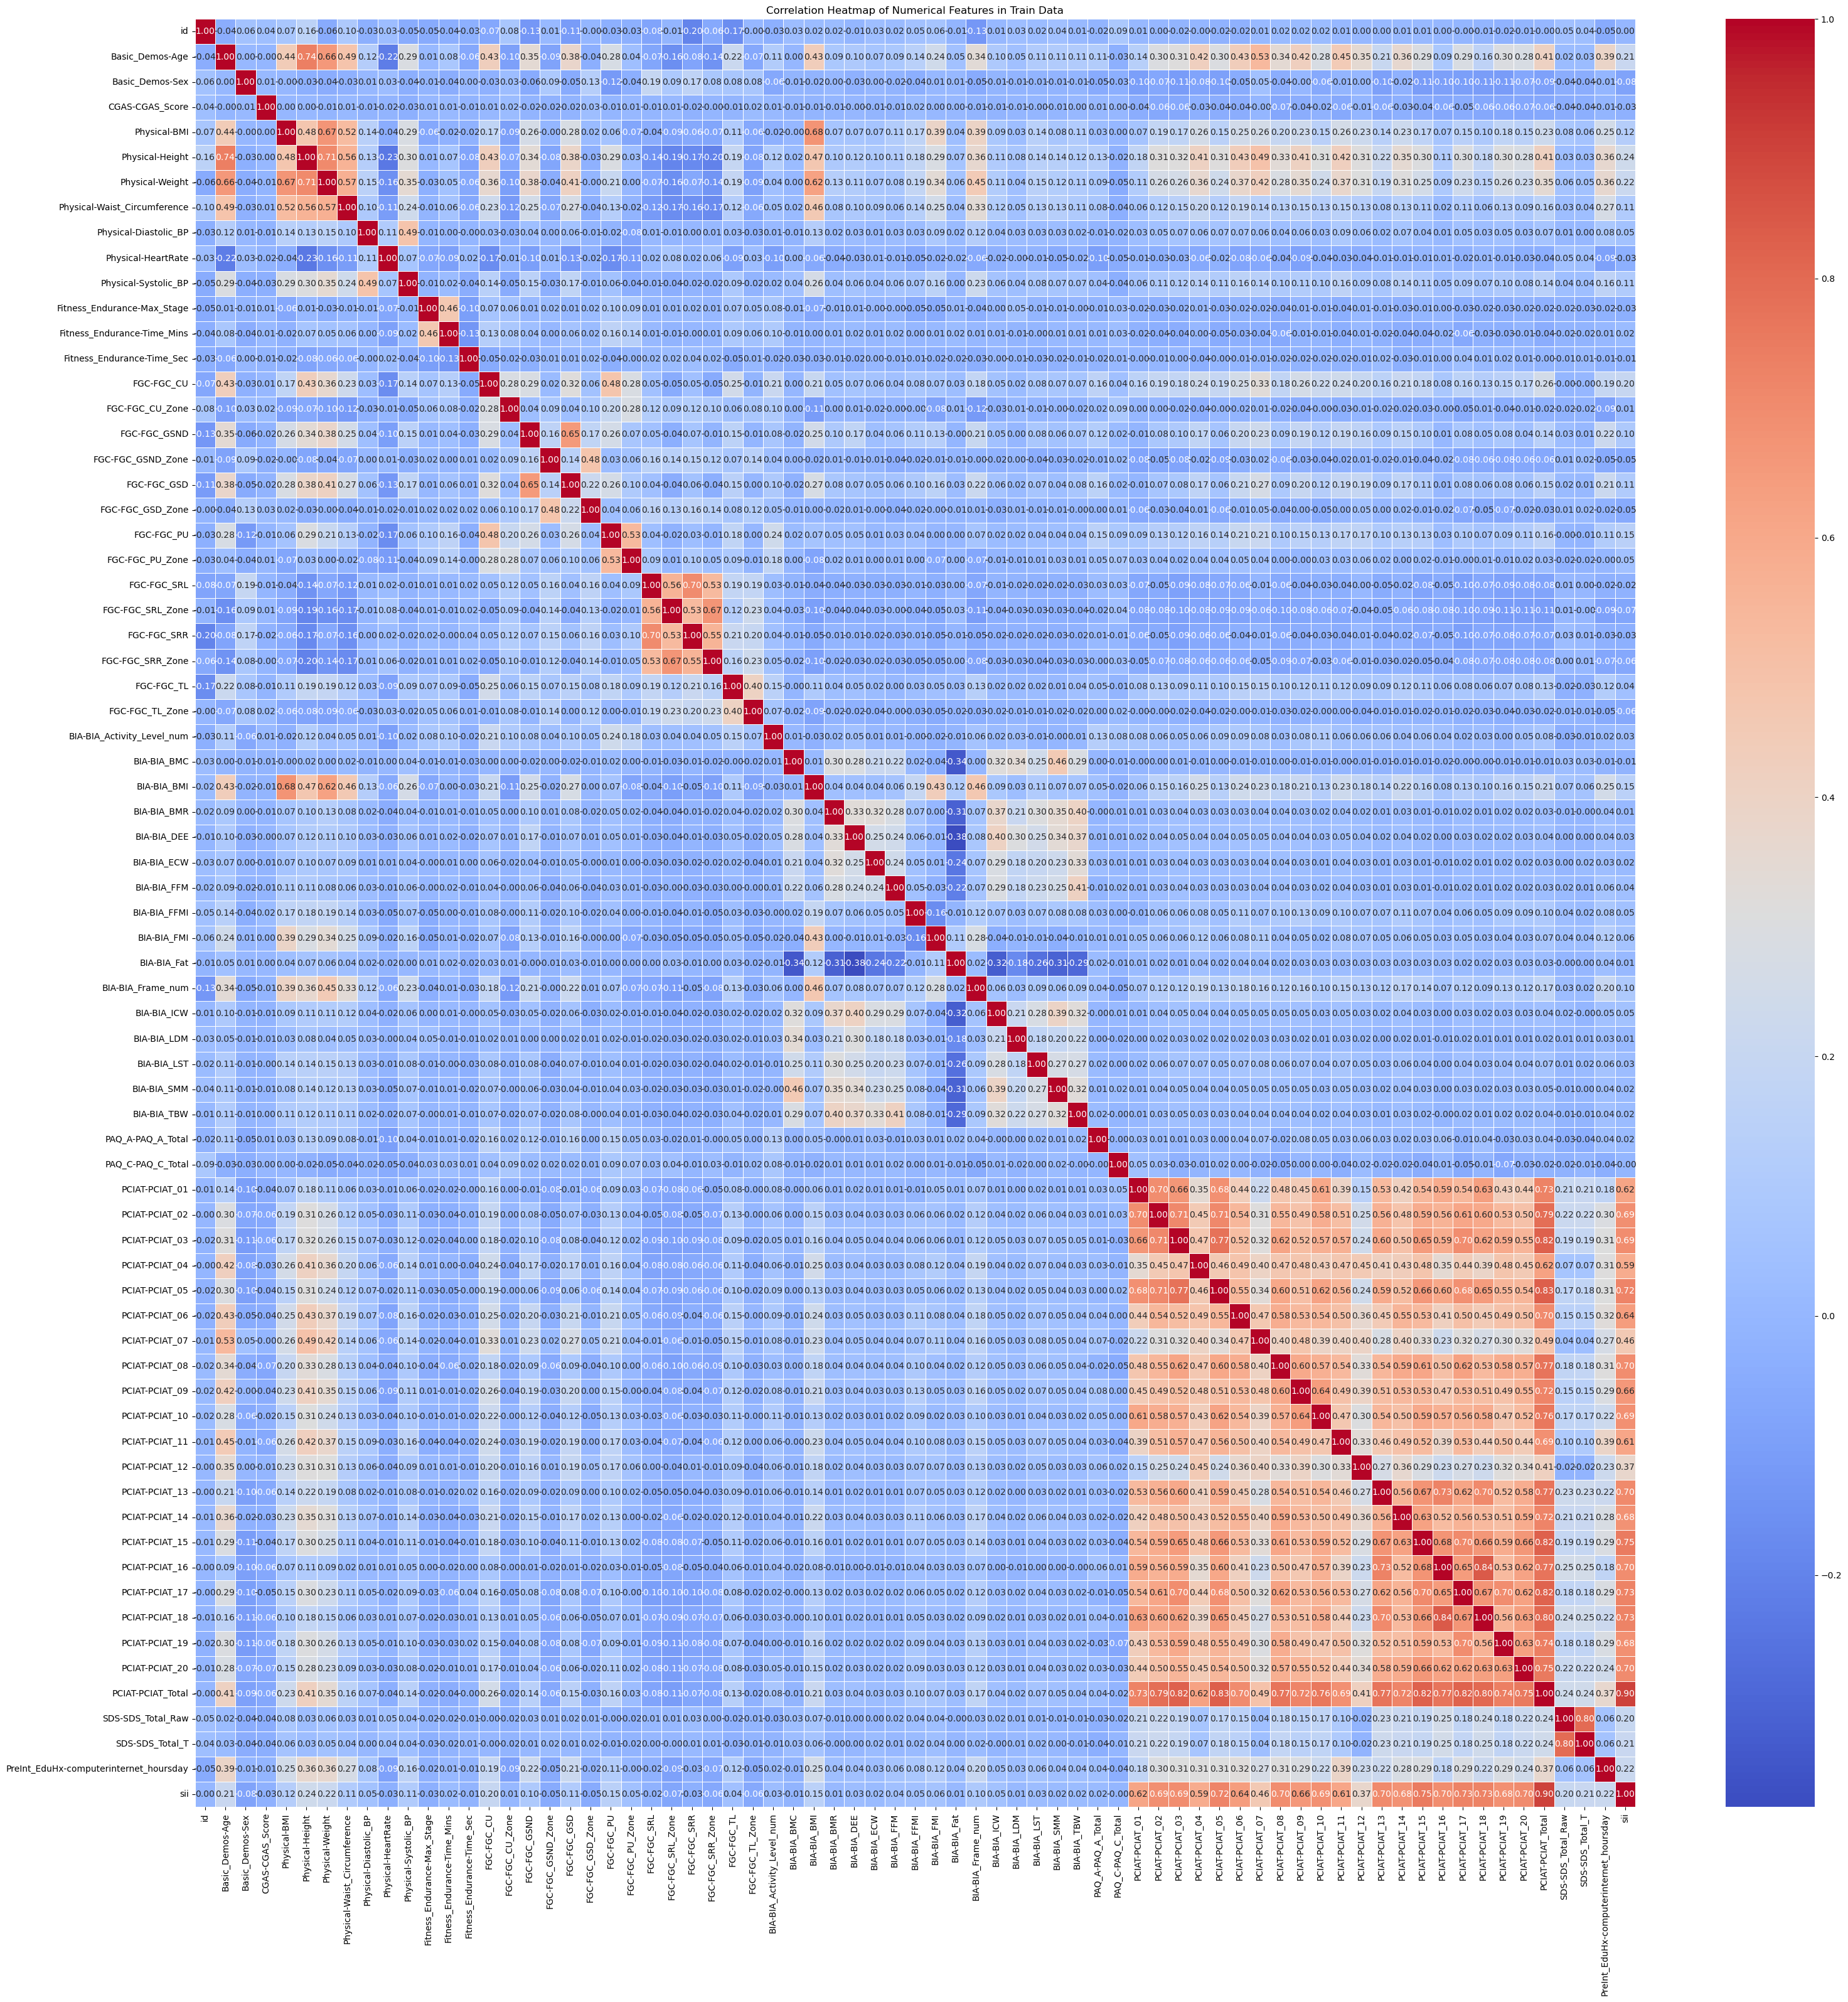

In [48]:
# Select only numerical columns for correlation matrix
numerical_columns = df.select_dtypes(include=['float64', 'int64'])

# Compute the correlation matrix
corr = numerical_columns.corr()

# Heatmap of correlation matrix
plt.figure(figsize=(32, 32))
sns.heatmap(corr, annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5)
plt.title('Correlation Heatmap of Numerical Features in Train Data')
plt.tight_layout()
#plt.show()

In [49]:
# Rimuovere 18+
# 0 = nan da lista
# paq Da arrotondare

# CGAS-CGAS_Score fuori scala

df_da_imp["CGAS-CGAS_Score"] = df_da_imp["CGAS-CGAS_Score"].mask(lambda x: x > 100, np.nan)

df_da_imp = df_da_imp[df_da_imp["Basic_Demos-Age"] <= 18]

colonne_zeri = ['Physical-Weight', 'Physical-Diastolic_BP', 'Physical-Systolic_BP']
df_da_imp[colonne_zeri] = df_da_imp[colonne_zeri].mask(lambda x: x == 0, np.nan)

'''
- le stagioni sono da lasciare. una volta imputate si arrotondano i valori che escono per il BMI. 
- i valori delle due colonne bmi sono diversi quindi lo ricalcoliamo noi dopo aver imputato altezza e peso
- da togliere Fitness_Endurance-Time_Mins e Fitness_Endurance-Time_Sec visto 
    che abbiamo crea to Fitness_Endurance-Tempo_totale che le include entrambe
- tutte le paq sono da rimuovere: troppi valori mancanti inoltre non ha senso visto che alcune righe sono considerate sia come 
    adolescenti che come bambini. anche ridondante visto che abbiamo già abbastanza valori sull'attività fisica.
    sono pure fuori scala'''

df_da_imp['Fitness_Endurance-Tempo_totale'] = df_da_imp['Fitness_Endurance-Time_Sec'] + \
    (df_da_imp['Fitness_Endurance-Time_Mins']*60)

df_da_imp= df_da_imp.drop(['Fitness_Endurance-Time_Mins','Fitness_Endurance-Time_Sec'], axis=1)

df_da_imp= df_da_imp.drop(['PAQ_A-Season','PAQ_A-PAQ_A_Total','PAQ_C-Season','PAQ_C-PAQ_C_Total'], axis=1)

df_da_imp= df_da_imp.drop(['Physical-BMI','BIA-BIA_BMI', 'SDS-SDS_Total_T'], axis=1)

In [50]:
variabili_cat = ['Basic_Demos-Enroll_Season','Basic_Demos-Sex','CGAS-Season',
'Physical-Season','Fitness_Endurance-Season','FGC-Season',
"FGC-FGC_CU_Zone", "FGC-FGC_GSND_Zone", "FGC-FGC_GSD_Zone",
"FGC-FGC_PU_Zone", "FGC-FGC_SRL_Zone", "FGC-FGC_SRR_Zone",
"FGC-FGC_TL_Zone",'BIA-Season','BIA-BIA_Activity_Level_num','BIA-BIA_Frame_num',
'PCIAT-Season', 'PCIAT-PCIAT_01', 'PCIAT-PCIAT_02', 'PCIAT-PCIAT_03',
'PCIAT-PCIAT_04', 'PCIAT-PCIAT_05', 'PCIAT-PCIAT_06', 'PCIAT-PCIAT_07',
'PCIAT-PCIAT_08', 'PCIAT-PCIAT_09', 'PCIAT-PCIAT_10', 'PCIAT-PCIAT_11',
'PCIAT-PCIAT_12', 'PCIAT-PCIAT_13', 'PCIAT-PCIAT_14', 'PCIAT-PCIAT_15',
'PCIAT-PCIAT_16', 'PCIAT-PCIAT_17', 'PCIAT-PCIAT_18', 'PCIAT-PCIAT_19',
'PCIAT-PCIAT_20','SDS-Season','PreInt_EduHx-Season',
'PreInt_EduHx-computerinternet_hoursday']

In [51]:
stagioni = {"Winter": 0, "Spring": 1, "Summer": 2, "Fall": 3}
df_lavoro = df_da_imp.replace(stagioni)

X_features = df_lavoro.drop(['id', 'sii', 'sds_imputed_mask'], axis=1)
df_sds_mask = df_lavoro['sds_imputed_mask']
y_target = df_lavoro['sii'].astype(int)
df_id = df_lavoro['id']

X_train, X_test, y_train, y_test, mask_train, mask_test = train_test_split(
    X_features, y_target, df_sds_mask, test_size=0.3, random_state=0, stratify=y_target
)

rf_estimator = RandomForestRegressor(n_estimators=20, random_state=222, n_jobs=-1)
imputer_rf = IterativeImputer(estimator=rf_estimator, random_state=222, max_iter=5)

X_train_imp_array = imputer_rf.fit_transform(X_train)
X_test_imp_array = imputer_rf.transform(X_test)

X_train_imp = pd.DataFrame(X_train_imp_array, columns=X_train.columns, index=X_train.index)
X_test_imp = pd.DataFrame(X_test_imp_array, columns=X_test.columns, index=X_test.index)

train_completo = X_train_imp.assign(sii=y_train, sds_imputed_mask=mask_train)
test_completo = X_test_imp.assign(sii=y_test, sds_imputed_mask=mask_test)

df_final_features = pd.concat([train_completo, test_completo]).sort_index()

df_final_features.insert(0, 'id', df_id)
df_imp_et = df_final_features  

/var/folders/dx/gml1dzlj4hv40xclhd6scg5r0000gn/T/ipykernel_48675/4261465097.py:2: FutureWarning:

Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`

/opt/anaconda3/lib/python3.13/site-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning:

[IterativeImputer] Early stopping criterion not reached.



In [52]:
df_imp_et[variabili_cat]= df_imp_et[variabili_cat].round() 
#df_imp_et["bmi"] = (df_imp_et["Physical-Weight"] / (df_imp_et["Physical-Height"] ** 2)) * 703


In [53]:
# Salvataggio dati in parquet
df_imp_et.to_parquet('df_imp_et.parquet')

# Outliers Detection

In [54]:
df_imp_et= pd.read_parquet('df_imp_et.parquet')
standard_scaler = StandardScaler().set_output(transform="pandas")
minmax_scaler = MinMaxScaler()

droppare_per_X= ['sii', 'id', 'sds_imputed_mask']

y=np.array(df_imp_et['sii'])
X = df_imp_et.drop(droppare_per_X, axis=1)
X_standard = pd.DataFrame(
    standard_scaler.fit_transform(X), 
    columns=X.columns, 
    index=X.index
)
y = y.astype(int)

X_train, X_test, _, _ = train_test_split(X_standard, y, test_size=0.3, random_state=0)

In [55]:
X_standard.to_parquet('X_standard.parquet')

In [56]:
# Ensemble: FeaBag

feabag_model = FeatureBagging(
    base_estimator=LOF(),  # stimatore base, si può cambiare
    n_estimators=100,  # da testare coi dati veri per capire quanto ci vuole
    max_features=0.5,  # proporzione di variabili da estrarre per ogni modello
    contamination=0.01,  # come prima, 1% di outliers
    random_state=222,
    n_jobs=-1 
)
feabag_model.fit(X_standard)

feabag_preds = feabag_model.predict(X_standard)

In [57]:
#Foreste: Extended Forest

# In isotree, ndim=1 equivale a Isolation Forest standard.
# Scegliere ndim=df.shape[1] per la Extended Isolation Forest completa.
extended_forest_model = EIF(
    sample_size=256,  # come prima
    ntrees=100,  # numero alberi
    # serve a dire al modello che vogliamo la versione estesa
    ndim=X_standard.shape[1],
    random_seed=222,
    n_jobs=-1
)
extended_forest_model.fit(X_standard)

# EIF genera uno score (più alto = più probabile outlier)
extended_forest_scores = extended_forest_model.predict(X_standard)

# gli outlier vanno trovati a mano
threshold = np.percentile(extended_forest_scores, 99)  # 99 percentile
extended_forest_preds = (extended_forest_scores > threshold).astype(int)

/opt/anaconda3/lib/python3.13/site-packages/isotree/__init__.py:97: UserWarning:

Attempting to use more than 1 thread, but package was built without multi-threading support - see the project's GitHub page for more information.

/opt/anaconda3/lib/python3.13/site-packages/isotree/__init__.py:1737: UserWarning:

Instantiating CategoricalDtype without any arguments.Pass a CategoricalDtype instance to silence this warning.

/opt/anaconda3/lib/python3.13/site-packages/isotree/__init__.py:1757: UserWarning:

Instantiating CategoricalDtype without any arguments.Pass a CategoricalDtype instance to silence this warning.



91


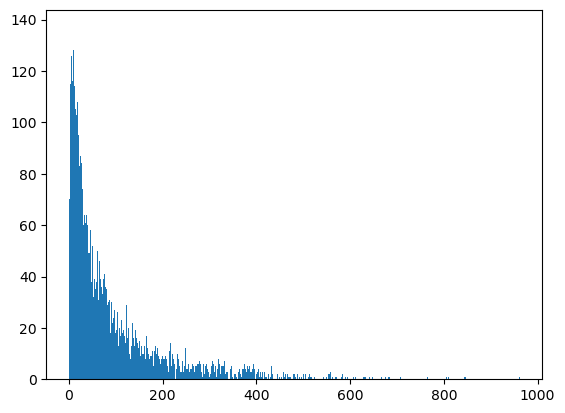

Numero di outlier trovati: 170 (2.04%)


In [58]:
import math as m
#Distanza: RKNN
# 1. Trova i k-vicini per ogni punto
k = int(m.sqrt(len(X_standard)))
nbrs = NearestNeighbors(n_neighbors=k).fit(X_standard)
distances, indices = nbrs.kneighbors(X_standard)
print(k)
# 2. Conta quante volte ogni indice compare nella matrice dei vicini
# 'indices' contiene gli indici dei k vicini per ogni riga
flat_indices = indices.flatten()
counts = np.bincount(flat_indices, minlength=len(X_standard))

# 3. Lo score RkNN è il conteggio (invertito)
# Più il conteggio è basso, più il punto è un outlier
rknn_scores = counts

out= np.percentile(rknn_scores, q=1)

outliers_rknn = np.zeros(len(rknn_scores))
outliers_rknn[rknn_scores <= out] = 1

plt.hist(rknn_scores, bins=range(int(np.max(rknn_scores))))
#plt.axvline(np.max(rknn_scores[np.where(out==1)]), c='k', linestyle='--')
plt.show()

n_outliers_rknn = np.sum(outliers_rknn)
print(f"Numero di outlier trovati: {int(n_outliers_rknn)} ({n_outliers_rknn/len(df_imp_et)*100:.2f}%)")



In [59]:
#Deviation-based Approaches: EllEnv

from sklearn.covariance import EllipticEnvelope

ellenv = EllipticEnvelope(random_state=222, contamination=0.01)
ellenv.fit(X_standard)

# predict returns 1 for an inlier and -1 for an outlier
outliers_ellenv = ellenv.predict(X_standard)

#print (outliers_ellenv)
np.unique(outliers_ellenv, return_counts=True)

n_outliers_ellenv = np.sum(outliers_ellenv == -1)
print(f"Numero di outlier trovati: {int(n_outliers_ellenv)} ({n_outliers_ellenv/len(df_imp_et)*100:.2f}%)")

/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-165.993847455678917 > -197.857676298030157). You may want to try with a higher value of support_fraction (current value: 0.505).

/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-165.952530794806194 > -198.839064278403328). You may want to try with a higher value of support_fraction (current value: 0.505).

/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-165.302906080719850 > -194.279140735432975). You may want to try with a higher value of support_fraction (current value: 0.505).

/opt/anaconda3/lib/python3.13/site-packages

Numero di outlier trovati: 84 (1.01%)


/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-166.206518752629393 > -228.442090645394671). You may want to try with a higher value of support_fraction (current value: 0.504).

/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-166.007834491606900 > -230.944150190910733). You may want to try with a higher value of support_fraction (current value: 0.504).

/opt/anaconda3/lib/python3.13/site-packages/sklearn/covariance/_robust_covariance.py:185: RuntimeWarning:

Determinant has increased; this should not happen: log(det) > log(previous_det) (-165.987101914400029 > -228.358102199565849). You may want to try with a higher value of support_fraction (current value: 0.504).

/opt/anaconda3/lib/python3.13/site-packages

In [60]:

# High Dimensionality: Fast ABOD

#!!! LENTO, su portatile in carica ci mette 5+ minuti; sul fisso un paio

# Contamination è la proporzione di outliers; n_neighbors autoesplicativo
abod_model = ABOD(contamination=0.01, n_neighbors=k, n_jobs=-1)
abod_model.fit(X_standard)

# 0 = inliers e 1 = outliers
abod_preds = abod_model.predict(X_standard)
abod_scores = abod_model.decision_scores_


In [61]:
df_outliers = pd.DataFrame(
    np.column_stack((outliers_rknn, outliers_ellenv,
                    feabag_preds, extended_forest_preds,abod_preds)),
    columns=['rknn', 'ellenv', 'feabag', 'ext_forest', 'abod']
)

df_outliers['risultati'] = (
    (df_outliers['rknn'] == 1).astype(int) +
    (df_outliers['ellenv'] == -1).astype(int) +
    (df_outliers['feabag'] == 1).astype(int) +
    (df_outliers['ext_forest'] == 1).astype(int) +
    (df_outliers['abod']== 1).astype(int)
)

df_outliers_2= df_outliers[df_outliers['risultati']>=2]
df_outliers_1= df_outliers[df_outliers['risultati']>=1]
df_outliers["colore"] = np.where(df_outliers["risultati"] >= 2, 1, 0)


In [62]:
# rimossi gli outliers che erano outliers per più di due metodi
df_risultati= df_imp_et.copy()
df_risultati['risultati'] = df_outliers['risultati'].values
df_pulito = df_risultati[df_risultati['risultati'] <= 1].copy()

print(f"Righe originali: {len(df_risultati)}")
print(f"Righe dopo il filtro: {len(df_pulito)}")

df_solo_out=df_risultati[df_risultati['risultati'] > 1].copy()

Righe originali: 8319
Righe dopo il filtro: 8225


In [63]:
# --- PREPARAZIONE DATASET PER REGRESSIONE ---
# Ora filtriamo df_pulito rimuovendo tutte le righe dove SDS_Total_Raw era stato imputato
df_regression = df_pulito[~df_pulito['sds_imputed_mask']].copy()

# Possiamo droppare la maschera visto che non serve più
df_regression = df_regression.drop(columns=['sds_imputed_mask'])

print(f"Righe in df_pulito (Classificazione): {len(df_pulito)}")
print(f"Righe in df_regression (Regressione su valori veri): {len(df_regression)}")

# Salviamo il dataset per i notebook successivi di regressione
df_regression.to_parquet('df_regression.parquet')


Righe in df_pulito (Classificazione): 8225
Righe in df_regression (Regressione su valori veri): 4788


In [64]:
df_pulito= df_pulito.drop('sds_imputed_mask', axis=1)

df_outliers.to_parquet('df_outliers.parquet')
df_pulito.to_parquet('df_pulito.parquet')

# Dimensionality Reduction


In [65]:
X_standard= pd.read_parquet('X_standard.parquet')
df_outliers= pd.read_parquet('df_outliers.parquet')

In [66]:
%%time
#PCA
pca = PCA(n_components=3, random_state=222)
df_unito_pca = pca.fit_transform(X_standard)
print(pca.explained_variance_ratio_.sum()) 

0.2891090118537558
CPU times: user 2.46 ms, sys: 1.88 ms, total: 4.34 ms
Wall time: 3.28 ms


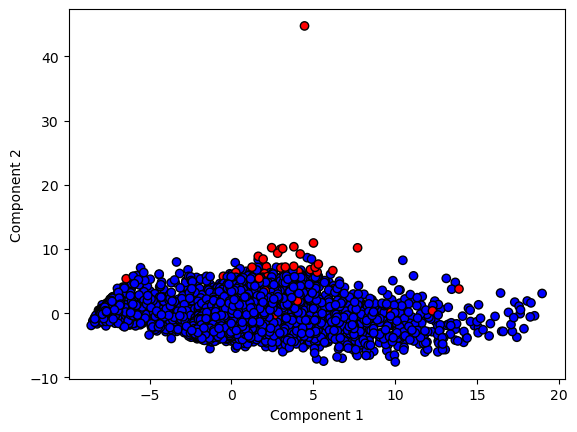

In [67]:
# 2D
fig, ax= plt.subplots()
plt.scatter(df_unito_pca[:, 0], df_unito_pca[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()

import plotly.express as px

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_pca[:, 0],
    'Component 2': df_unito_pca[:, 1],
    'Component 3': df_unito_pca[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Viridis', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()



In [68]:
%%time
import umap
#UMAP
umappe = umap.UMAP(n_components = 3, n_jobs=-1)
df_unito_umap = umappe.fit_transform(X_standard)

print(umappe)

UMAP(n_components=3, tqdm_kwds={'bar_format': '{desc}: {percentage:3.0f}%| {bar} {n_fmt}/{total_fmt} [{elapsed}]', 'desc': 'Epochs completed', 'disable': True})
CPU times: user 17.2 s, sys: 4.9 s, total: 22.1 s
Wall time: 2.31 s


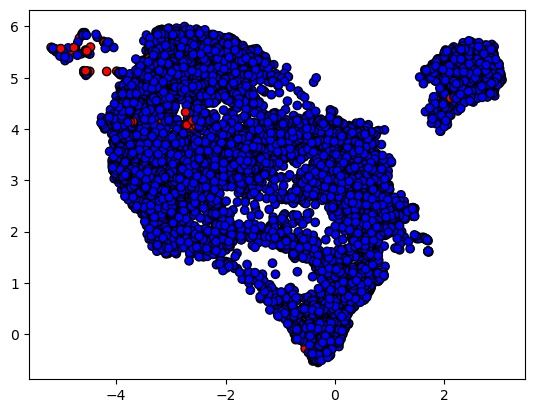

In [69]:
# 2D

plt.scatter(df_unito_umap[:, 0], df_unito_umap[:, 1],
            c=df_outliers['colore'], cmap=plt.cm.bwr, edgecolor='k', alpha=1)

ax.set_xlabel('Component 1')
ax.set_ylabel('Component 2')

plt.show()
import plotly.express as px
import pandas as pd

# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_umap[:, 0],
    'Component 2': df_unito_umap[:, 1],
    'Component 3': df_unito_umap[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()


In [70]:
tsne = TSNE(n_components=3, n_jobs=-1)
df_unito_tsne = tsne.fit_transform(X_standard)
X_standard.shape

(8319, 72)

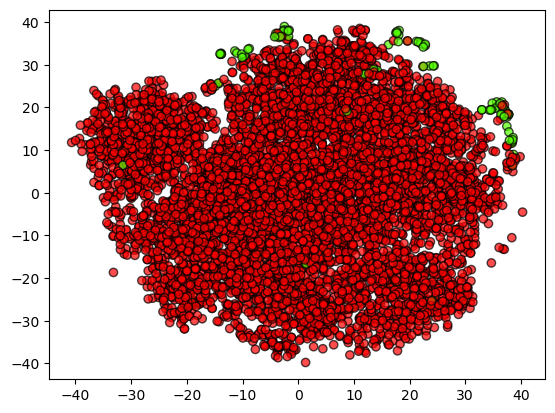

In [71]:
plt.scatter(df_unito_tsne[:, 0], df_unito_tsne[:, 1], c=df_outliers['colore'], cmap=plt.cm.prism, edgecolor='k', alpha=0.7)
plt.show()


# 1. Prepariamo il DataFrame
df_plot = pd.DataFrame({
    'Component 1': df_unito_tsne[:, 0],
    'Component 2': df_unito_tsne[:, 1],
    'Component 3': df_unito_tsne[:, 2],
    'Colore': df_outliers['colore']
})

# 2. Creiamo lo scatter 3D con punti piccoli e nuovi colori
fig = px.scatter_3d(
    df_plot,
    x='Component 1',
    y='Component 2',
    z='Component 3',
    color='Colore',
    # --- MODIFICHE QUI ---
    color_continuous_scale='Plasma', # Cambia scala: 'Viridis', 'Plasma', 'Inferno', 'Turbo'
    opacity=0.7,                     # Leggera trasparenza aiuta a vedere la densità
)

# 3. Rimpicciolire i punti
# Plotly usa un default di circa 20. Impostando un valore fisso basso:
fig.update_traces(marker=dict(size=3)) # Prova valori tra 2 e 5

# 4. Opzionale: Titolo e layout
fig.update_layout(title="Analisi Outlier - Punti Rimpiccioliti")

fig.show()
